In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
import joblib
import os

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

print("✅ Libraries loaded")

✅ Libraries loaded


In [2]:
df = pd.read_parquet("data/features_demand.parquet")
df['sale_date'] = pd.to_datetime(df['sale_date'])

print(f"عدد الصفوف: {len(df):,}")
print(f"الفترة: من {df['sale_date'].min().date()} إلى {df['sale_date'].max().date()}")
df.head()

عدد الصفوف: 2,956
الفترة: من 2024-10-13 إلى 2026-10-13


,product_id,store_id,sale_date,quantity_sold,revenue,num_transactions,avg_discount,avg_unit_price,product_name,category_id,category_name,store_name,store_city,store_country,lag_1,lag_7,lag_14,lag_30,rolling_mean_7,rolling_mean_14,rolling_std_7,year,month,day_of_week,is_weekend,quarter
0,1,3,2025-11-28 10:38:03.277856+00:00,1,85.550105,1,13.05,98.39,Progressive discrete implementation,5,Sports,Obrien-Carson Store,Port Mitchell,Paraguay,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025,11,4,0,4
1,1,3,2025-12-07 16:28:59.688785+00:00,2,196.780000,1,0.00,98.39,Progressive discrete implementation,5,Sports,Obrien-Carson Store,Port Mitchell,Paraguay,1.0,NaN,NaN,NaN,1.0,1.0,NaN,2025,12,6,1,4
2,1,12,2026-09-29 20:25:55.240250+00:00,3,295.170000,1,0.00,98.39,Progressive discrete implementation,5,Sports,"Li, Melton and Smith Store",Susanville,Suriname,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026,9,1,0,3
3,1,14,2025-03-02 14:23:20.322665+00:00,4,393.560000,1,0.00,98.39,Progressive discrete implementation,5,Sports,Garza-Henderson Store,North Mistyside,Greenland,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025,3,6,1,1
4,1,15,2025-12-01 10:41:23.710006+00:00,3,295.170000,1,0.00,98.39,Progressive discrete implementation,5,Sports,"Fuentes, Lewis and Norman Store",Jasonfort,Iraq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025,12,0,0,4


In [5]:
# الميزات المستخدمة في التدريب
feature_cols = [
    'lag_1', 'lag_7',
    'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7',
    'avg_discount', 'avg_unit_price',
    'day_of_week', 'is_weekend', 'month', 'quarter'
]

target_col = 'quantity_sold'

df_model = df.copy()

# نملأ القيم الناقصة بدل حذفها
df_model[feature_cols] = df_model[feature_cols].fillna(0)

print(f"عدد الصفوف بعد التنظيف: {len(df_model):,}")
print(f"الميزات المستخدمة: {feature_cols}")

عدد الصفوف بعد التنظيف: 2,956
الميزات المستخدمة: ['lag_1', 'lag_7', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'avg_discount', 'avg_unit_price', 'day_of_week', 'is_weekend', 'month', 'quarter']


In [6]:
# نقسم حسب التاريخ (آخر 20% للاختبار)
df_model = df_model.sort_values('sale_date')

split_idx = int(len(df_model) * 0.8)
train = df_model.iloc[:split_idx]
test = df_model.iloc[split_idx:]

X_train = train[feature_cols]
y_train = train[target_col]
X_test = test[feature_cols]
y_test = test[target_col]

print(f"Train size: {len(train):,}")
print(f"Test size : {len(test):,}")
print(f"Train period: {train['sale_date'].min().date()} → {train['sale_date'].max().date()}")
print(f"Test period : {test['sale_date'].min().date()} → {test['sale_date'].max().date()}")

Train size: 2,364
Test size : 592
Train period: 2024-10-13 → 2026-06-03
Test period : 2026-06-03 → 2026-10-13


In [7]:
model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

print("⏳ جاري تدريب النموذج...")
model.fit(X_train, y_train)
print("✅ تم التدريب بنجاح")

⏳ جاري تدريب النموذج...
✅ تم التدريب بنجاح


In [8]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = np.mean(np.abs((y_test - y_pred) / (y_test + 1e-6))) * 100

print("="*50)
print("📊 نتائج التقييم على بيانات الاختبار")
print("="*50)
print(f"MAE  (Mean Absolute Error) : {mae:.3f}")
print(f"RMSE (Root Mean Squared Error): {rmse:.3f}")
print(f"MAPE (Mean Absolute % Error) : {mape:.2f}%")

📊 نتائج التقييم على بيانات الاختبار
MAE  (Mean Absolute Error) : 1.045
RMSE (Root Mean Squared Error): 1.212
MAPE (Mean Absolute % Error) : 58.13%


            feature  importance
6    avg_unit_price    0.141323
9             month    0.116656
5      avg_discount    0.109754
3   rolling_mean_14    0.107182
10          quarter    0.101297
7       day_of_week    0.100418
8        is_weekend    0.092038
2    rolling_mean_7    0.085890
0             lag_1    0.078654
4     rolling_std_7    0.066788
1             lag_7    0.000000


/tmp/ipykernel_36650/1812386511.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance, x='importance', y='feature', palette='viridis')


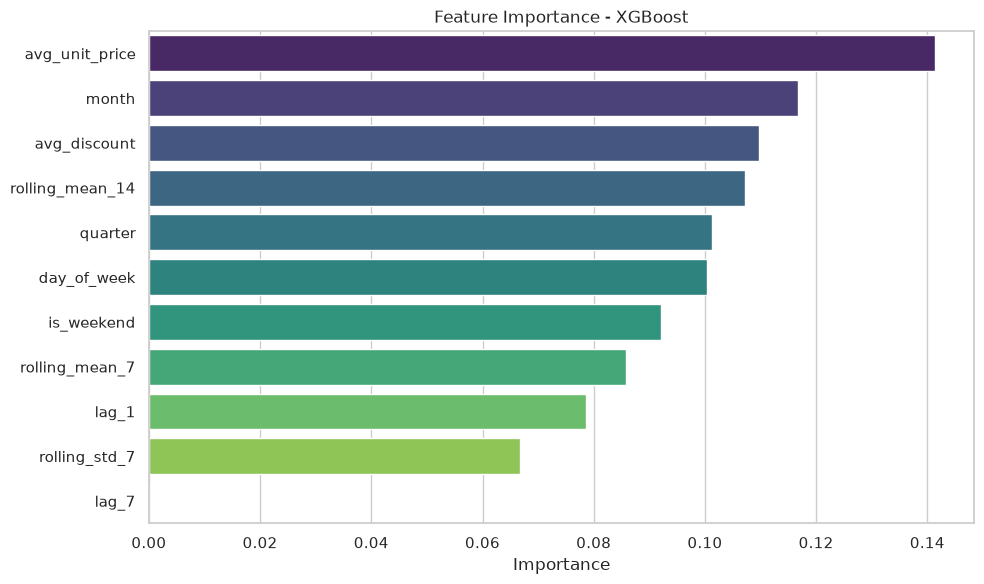

In [9]:
importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

print(importance)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance, x='importance', y='feature', palette='viridis')
plt.title('Feature Importance - XGBoost')
plt.xlabel('Importance')
plt.ylabel('')
plt.tight_layout()
plt.show()

أكثر 5 تركيبات Product + Store من حيث عدد النقاط:
     product_id  store_id  count
187         167         9      2
463         402        19      2
465         403         6      2
115         103        12      2
194         175        18      2

تم اختيار → Product ID: 167 | Store ID: 9 | عدد النقاط: 2


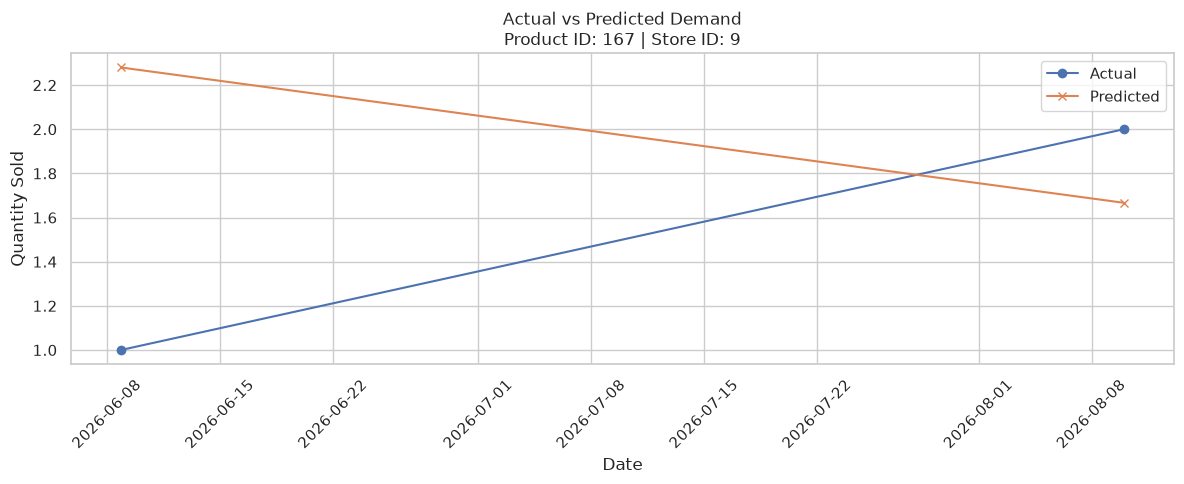

In [11]:
results = test[['sale_date', 'product_id', 'store_id', 'quantity_sold']].copy()
results['predicted'] = y_pred

# نبحث عن أكثر Product+Store عندهم بيانات في الـ test
sample = (
    results.groupby(['product_id', 'store_id'])
    .size()
    .reset_index(name='count')
    .sort_values('count', ascending=False)
)

print("أكثر 5 تركيبات Product + Store من حيث عدد النقاط:")
print(sample.head())

# نأخذ أول واحد عنده على الأقل نقطتين
valid = sample[sample['count'] >= 2]

if len(valid) == 0:
    print("\n⚠️ لا يوجد Product+Store عنده نقطتين أو أكثر في بيانات الاختبار.")
    print("هنرسم مقارنة عامة بدلًا من ذلك:")
    
    # رسم عام: Actual vs Predicted
    plt.figure(figsize=(8, 8))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Perfect Prediction')
    plt.xlabel('Actual Quantity')
    plt.ylabel('Predicted Quantity')
    plt.title('Actual vs Predicted (All Test Data)')
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    pid = valid.iloc[0]['product_id']
    sid = valid.iloc[0]['store_id']
    
    plot_df = results[
        (results['product_id'] == pid) & 
        (results['store_id'] == sid)
    ].sort_values('sale_date')
    
    print(f"\nتم اختيار → Product ID: {pid} | Store ID: {sid} | عدد النقاط: {len(plot_df)}")
    
    plt.figure(figsize=(12, 5))
    plt.plot(plot_df['sale_date'], plot_df['quantity_sold'], label='Actual', marker='o')
    plt.plot(plot_df['sale_date'], plot_df['predicted'], label='Predicted', marker='x')
    plt.title(f'Actual vs Predicted Demand\nProduct ID: {pid} | Store ID: {sid}')
    plt.xlabel('Date')
    plt.ylabel('Quantity Sold')
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
plt.show()